C:\Users\Admin\anaconda3\envs\test_env\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):






Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 reshape (Reshape)           (None, 28, 28, 1)         0         
                                                                 
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2  (None, 13, 13, 32)        0         
 D)                                                              
                                                                 
 flatten (Flatten)           (None, 5408)              0         
                                                                 
 dense (Dense)               (None, 128)               692352    
                                                                 
 dense_1 (Dense)             (None, 10)                1290      
                                                    

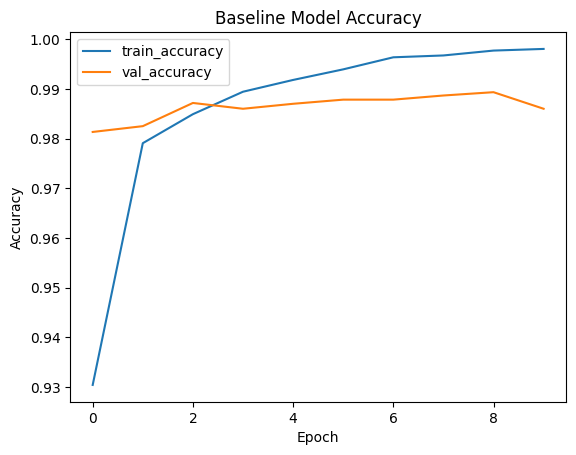

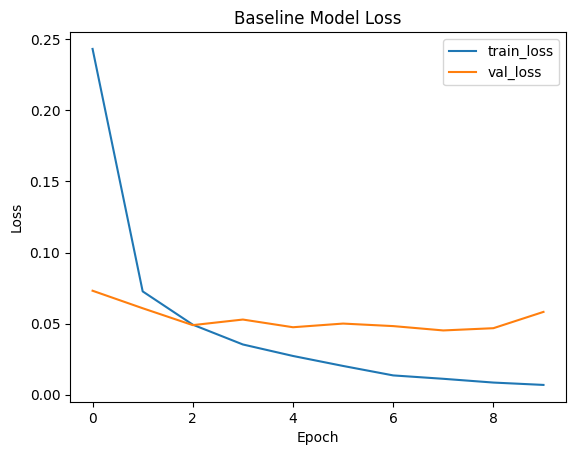

Baseline test accuracy: 0.9858
Saved baseline model to: C:\Users\Admin\AppData\Local\Temp\tmpdbyvsspg.h5


C:\Users\Admin\anaconda3\envs\test_env\Lib\site-packages\tf_keras\src\engine\training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 reshape_1 (Reshape)         (None, 28, 28, 1)         0         
                                                                 
 prune_low_magnitude_conv2d  (None, 26, 26, 32)        610       
 _1 (PruneLowMagnitude)                                          
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 13, 13, 32)        0         
 g2D)                                                            
                                                                 
 flatten_1 (Flatten)         (None, 5408)              0         
                                                                 
 prune_low_magnitude_dense_  (None, 128)               1384578   
 2 (PruneLowMagnitude)                                           
                                                      

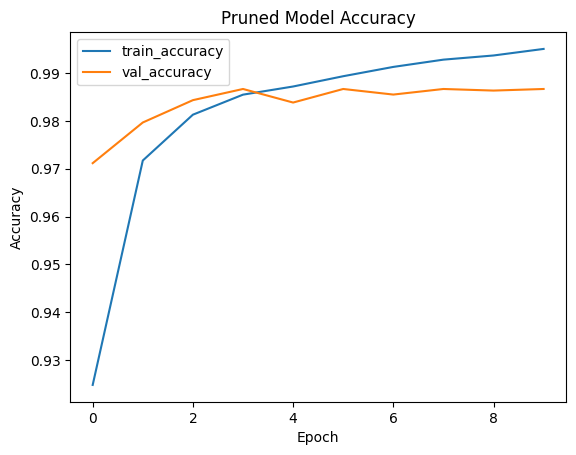

Saved pruned Keras model to: C:\Users\Admin\AppData\Local\Temp\tmp2l1mzu6z.h5
INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\tmphw_3qe08\assets


INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\tmphw_3qe08\assets


Saved pruned TFLite model to: C:\Users\Admin\AppData\Local\Temp\tmpoooonx2i.tflite
INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\tmpuvuek3t8\assets


INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\tmpuvuek3t8\assets


Saved quantized & pruned TFLite model to: C:\Users\Admin\AppData\Local\Temp\tmpwyeunoeo.tflite
                 Model  Size (bytes)
0       Baseline Keras       2584664
1         Pruned Keras        832455
2        Pruned TFLite        808642
3  Pruned+Quant TFLite        240397


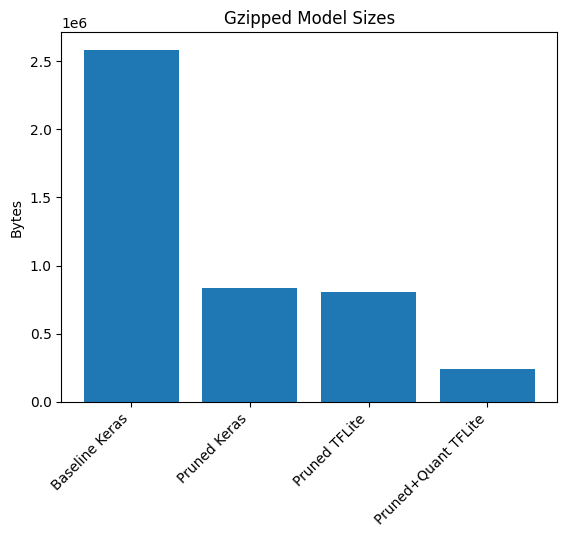

In [1]:
## Pruning and Quantization on MNIST

# 1. Install and Import Dependencies
!pip install -q tensorflow-model-optimization

import os
import tempfile
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
import tensorflow_model_optimization as tfmot

# 2. Load & Preprocess MNIST
(train_images, train_labels), (test_images, test_labels) = keras.datasets.mnist.load_data()
train_images = train_images.astype("float32") / 255.0
test_images  = test_images.astype("float32")  / 255.0

# 3. Define & Train Baseline Model
baseline_model = keras.Sequential([
    keras.layers.InputLayer(input_shape=(28,28)),
    keras.layers.Reshape((28,28,1)),
    keras.layers.Conv2D(32, (3,3), activation='relu'),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10)
])

baseline_model.compile(
    optimizer='adam',
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

print(baseline_model.summary())
history = baseline_model.fit(
    train_images, train_labels,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# Plot baseline training curves
plt.figure()
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.title('Baseline Model Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.show()

plt.figure()
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('Baseline Model Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.show()

# Evaluate & save baseline
_, baseline_acc = baseline_model.evaluate(test_images, test_labels, verbose=0)
print(f"Baseline test accuracy: {baseline_acc:.4f}")
_, keras_file = tempfile.mkstemp('.h5')
baseline_model.save(keras_file, include_optimizer=False)
print(f"Saved baseline model to: {keras_file}")

# 4. Apply Pruning
batch_size = 128
prune_epochs = 10
steps_per_epoch = np.ceil(len(train_images) / batch_size).astype(np.int32)
end_step = steps_per_epoch * prune_epochs

prune_low_magnitude = tfmot.sparsity.keras.prune_low_magnitude
def build_pruned_model():
    model = keras.Sequential([
        keras.layers.InputLayer(input_shape=(28,28)),
        keras.layers.Reshape((28,28,1)),
        prune_low_magnitude(keras.layers.Conv2D(32, (3,3), activation='relu'), pruning_schedule=tfmot.sparsity.keras.PolynomialDecay(0.50, 0.80, 0, end_step)),
        keras.layers.MaxPooling2D((2,2)),
        keras.layers.Flatten(),
        prune_low_magnitude(keras.layers.Dense(128, activation='relu'), pruning_schedule=tfmot.sparsity.keras.PolynomialDecay(0.50, 0.80, 0, end_step)),
        prune_low_magnitude(keras.layers.Dense(10), pruning_schedule=tfmot.sparsity.keras.PolynomialDecay(0.50, 0.80, 0, end_step))
    ])
    return model

model_for_pruning = build_pruned_model()
model_for_pruning.compile(
    optimizer='adam',
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)
print(model_for_pruning.summary())

callbacks = [tfmot.sparsity.keras.UpdatePruningStep()]

prune_history = model_for_pruning.fit(
    train_images, train_labels,
    batch_size=batch_size,
    epochs=prune_epochs,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

# Plot pruning training curves
plt.figure()
plt.plot(prune_history.history['accuracy'], label='train_accuracy')
plt.plot(prune_history.history['val_accuracy'], label='val_accuracy')
plt.title('Pruned Model Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.show()

# 5. Strip and Save Pruned Model
model_for_export = tfmot.sparsity.keras.strip_pruning(model_for_pruning)
_, pruned_keras_file = tempfile.mkstemp('.h5')
model_for_export.save(pruned_keras_file, include_optimizer=False)
print(f"Saved pruned Keras model to: {pruned_keras_file}")
_, pruned_tflite_file = tempfile.mkstemp('.tflite')
converter = tf.lite.TFLiteConverter.from_keras_model(model_for_export)
pruned_tflite_model = converter.convert()
with open(pruned_tflite_file, 'wb') as f:
    f.write(pruned_tflite_model)
print(f"Saved pruned TFLite model to: {pruned_tflite_file}")

# 6. Quantization + Pruning
converter = tf.lite.TFLiteConverter.from_keras_model(model_for_export)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
quant_pruned_tflite = converter.convert()
_, quant_pruned_file = tempfile.mkstemp('.tflite')
with open(quant_pruned_file, 'wb') as f:
    f.write(quant_pruned_tflite)
print(f"Saved quantized & pruned TFLite model to: {quant_pruned_file}")

# 7. Measure Compressed Sizes
def get_gzipped_model_size(file_path):
    _, zip_path = tempfile.mkstemp('.zip')
    with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        z.write(file_path)
    return os.path.getsize(zip_path)

sizes = {
    'Baseline Keras': get_gzipped_model_size(keras_file),
    'Pruned Keras': get_gzipped_model_size(pruned_keras_file),
    'Pruned TFLite': get_gzipped_model_size(pruned_tflite_file),
    'Pruned+Quant TFLite': get_gzipped_model_size(quant_pruned_file)
}

# Tabulate and Plot
df = pd.DataFrame(list(sizes.items()), columns=['Model','Size (bytes)'])
print(df)

plt.figure()
plt.bar(df['Model'], df['Size (bytes)'])
plt.title('Gzipped Model Sizes')
plt.ylabel('Bytes')
plt.xticks(rotation=45, ha='right')
plt.show()


In [4]:
import matplotlib.pyplot as plt
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42


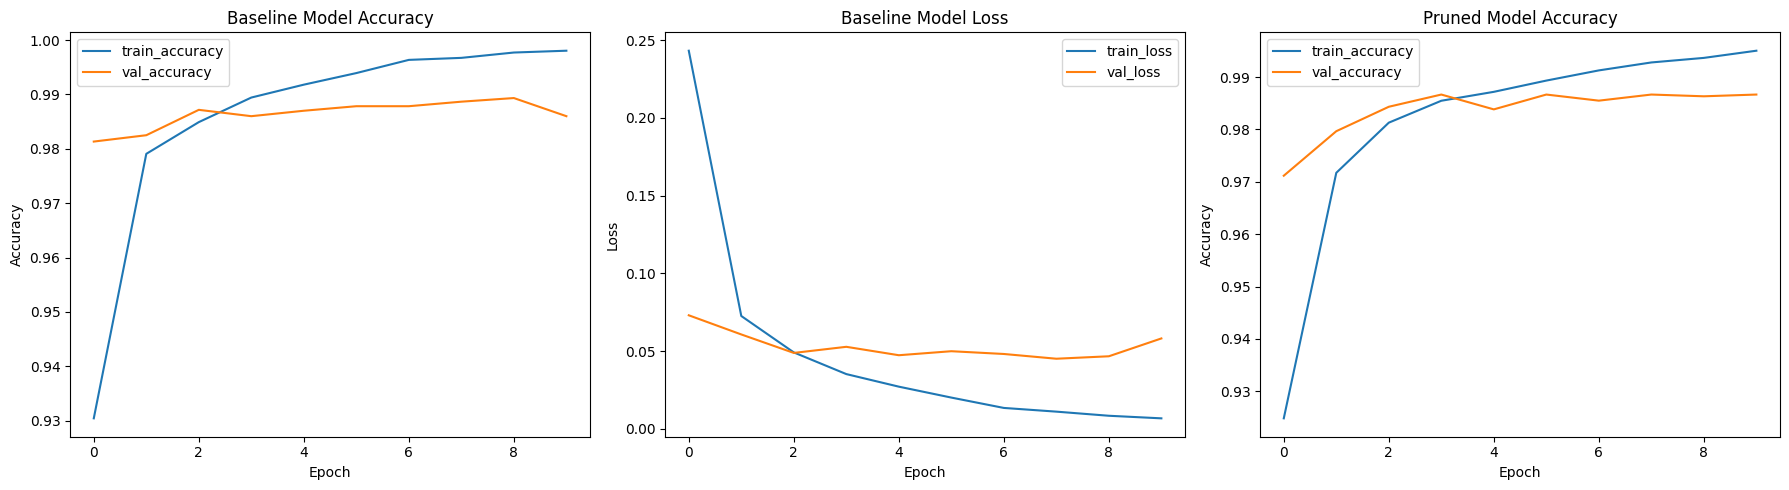

In [10]:
import matplotlib.pyplot as plt

# Create 1 row and 3 columns
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Baseline Model Accuracy
axs[0].plot(history.history['accuracy'], label='train_accuracy')
axs[0].plot(history.history['val_accuracy'], label='val_accuracy')
axs[0].set_title('Baseline Model Accuracy')
axs[0].set_xlabel('Epoch')
axs[0].set_ylabel('Accuracy')
axs[0].legend()

# Plot 2: Baseline Model Loss
axs[1].plot(history.history['loss'], label='train_loss')
axs[1].plot(history.history['val_loss'], label='val_loss')
axs[1].set_title('Baseline Model Loss')
axs[1].set_xlabel('Epoch')
axs[1].set_ylabel('Loss')
axs[1].legend()

# Plot 3: Pruned Model Accuracy
axs[2].plot(prune_history.history['accuracy'], label='train_accuracy')
axs[2].plot(prune_history.history['val_accuracy'], label='val_accuracy')
axs[2].set_title('Pruned Model Accuracy')
axs[2].set_xlabel('Epoch')
axs[2].set_ylabel('Accuracy')
axs[2].legend()

plt.tight_layout()
plt.savefig('model1.pdf')
plt.show()
